<a href="https://colab.research.google.com/github/anastasia-kotselivska/ITA/blob/main/lab4/Lab4_OCR_Kotselivska.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install easyocr opencv-python matplotlib

In [29]:
import cv2
import easyocr
import matplotlib.pyplot as plt
import json

IMAGE_PATH = "receipt.jpg"

# Зчитування зображення (OpenCV за замовчуванням використовує формат BGR)
img = cv2.imread(IMAGE_PATH)
# Перетворення зображення у відтінки сірого для покращення точності OCR
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Перетворення BGR у RGB для коректного відображення через matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [30]:
print("[*] Ініціалізація моделей EasyOCR...")
# Вказуємо підтримку української та англійської мов
reader = easyocr.Reader(['uk', 'en'], gpu=False)
print("[*] Виконання розпізнавання тексту...")
# Передаємо чорно-біле зображення на аналіз
results = reader.readtext(gray_img)
print(f"[+] Знайдено {len(results)} текстових блоків.")

[*] Ініціалізація моделей EasyOCR...
[*] Виконання розпізнавання тексту...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[+] Знайдено 67 текстових блоків.


Текст: TOB "ТОРГUВА ГРУПА "APC-KEPAМІКА | Точність: 0.26
Текст: Н # Г # 3 # H | Точність: 0.17
Текст: УKРАІНА , ІВАІО-ФРАНКІВСЬКА OEЛ . | Точність: 0.22
Текст: М ІВАНО-ФРАНКІВСЬК | Точність: 0.94
Текст: ВУЛ: КОБИЛЯНСЬКОі,56 | Точність: 0.66
Текст: ПН 325497319188 | Точність: 0.99
Текст: Кaca 09 | Точність: 0.54
Текст: ВІдділ Супернаркет | Точність: 0.85
Текст: Касир 160/12670 | Точність: 0.92
Текст: К9 ПК121 14/2/ | Точність: 0.75
Текст: 2263088 | Точність: 0.52
Текст: Штрих код 4820242913786 | Точність: 0.83
Текст: 1049932 Eskaro Стрічка малярна дел | Точність: 0.80
Текст: фІол | Точність: 0.92
Текст: ЕКСПЕРТ 48нН х 50н %0МКН | Точність: 0.13
Текст: 351.14 | Точність: 1.00
Текст: Ж 129.01 | Точність: 0.38
Текст: Штрих код 5902120208609 | Точність: 0.89
Текст: 654422 GRUVER Гернетик акриЛовнй А | Точність: 0.53
Текст: 100 ЗООНЛ | Точність: 0.99
Текст: б ІЛИЙ | Точність: 0.30
Текст: 258.02 | Точність: 0.49
Текст: Ж 146.47 | Точність: 0.80
Текст: Штрих код 5902120205707 | Точність: 0.81


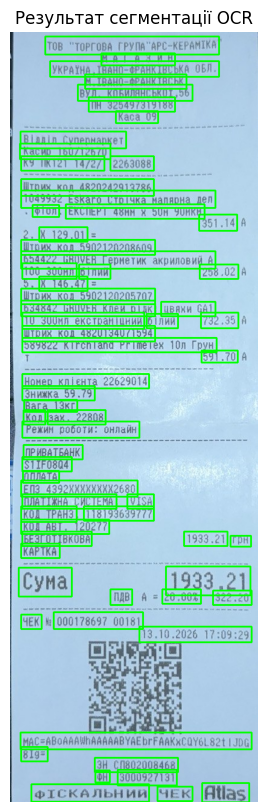

In [31]:
# Створюємо копію зображення для малювання
output_img = img_rgb.copy()
extracted_text_lines = []
for bbox, text, confidence in results:
  # Витягуємо координати точок (верхня ліва та нижня права)
  top_left = tuple([int(val) for val in bbox[0]])
  bottom_right = tuple([int(val) for val in bbox[2]])
  # Малюємо прямокутник: зображення, координати, колір (R,G,B), товщина лінії
  cv2.rectangle(output_img, top_left, bottom_right, (0, 255, 0), 2)
  # Зберігаємо текст, якщо рівень впевненості вищий за 30%
  if confidence > 0.3:
    extracted_text_lines.append(text)
  print(f"Текст: {text} | Точність: {confidence:.2f}")
# Виведення результату на екран
plt.figure(figsize=(10, 10))
plt.imshow(output_img)
plt.axis('off')
plt.title("Результат сегментації OCR")
plt.show()

In [32]:
# Об'єднання всіх розпізнаних рядків через перенесення рядка
full_raw_text = "\n".join(extracted_text_lines)
# Збереження у текстовий файл
output_filename = "ocr_result.txt"
with open(output_filename, "w", encoding="utf-8") as file:
  file.write(full_raw_text)
print(f"\n[✓] Сирий текст успішно збережено у файл: {output_filename}")
print("-" * 30)
print(full_raw_text[:200] + "...\n[Кінець фрагмента]")


[✓] Сирий текст успішно збережено у файл: ocr_result.txt
------------------------------
М ІВАНО-ФРАНКІВСЬК
ВУЛ: КОБИЛЯНСЬКОі,56
ПН 325497319188
Кaca 09
ВІдділ Супернаркет
Касир 160/12670
К9 ПК121 14/2/
2263088
Штрих код 4820242913786
1049932 Eskaro Стрічка малярна дел
фІол
351.14
Ж 129.0...
[Кінець фрагмента]


[*] Запуск експерименту (Варіант 6: Засвічення / Brightness)
[*] Оригінал: блоків = 62, середня впевненість = 0.75
[*] Критерії зупинки: Avg Confidence < 0.4 АБО блоків <= 31.0

beta =   0 | Блоків: 62 (100.0%) | Avg Conf: 0.750
beta =  10 | Блоків: 63 (101.6%) | Avg Conf: 0.753
beta =  20 | Блоків: 65 (104.8%) | Avg Conf: 0.735
beta =  30 | Блоків: 63 (101.6%) | Avg Conf: 0.747
beta =  40 | Блоків: 62 (100.0%) | Avg Conf: 0.758
beta =  50 | Блоків: 62 (100.0%) | Avg Conf: 0.744
beta =  60 | Блоків: 66 (106.5%) | Avg Conf: 0.716
beta =  70 | Блоків: 67 (108.1%) | Avg Conf: 0.662
beta =  80 | Блоків: 67 (108.1%) | Avg Conf: 0.694
beta =  90 | Блоків: 61 ( 98.4%) | Avg Conf: 0.666
beta = 100 | Блоків: 45 ( 72.6%) | Avg Conf: 0.631
beta = 110 | Блоків: 42 ( 67.7%) | Avg Conf: 0.630
beta = 120 | Блоків: 49 ( 79.0%) | Avg Conf: 0.526
beta = 130 | Блоків: 30 ( 48.4%) | Avg Conf: 0.501

[!] Досягнуто межу відмовостійкості при beta = 130


,Beta (яскравість),Розпізнано блоків,Відсоток від оригіналу (%),Середня впевненість
0,0,62,100.0,0.750
1,10,63,101.6,0.753
2,20,65,104.8,0.735
3,30,63,101.6,0.747
4,40,62,100.0,0.758
5,50,62,100.0,0.744
6,60,66,106.5,0.716
7,70,67,108.1,0.662
8,80,67,108.1,0.694
9,90,61,98.4,0.666


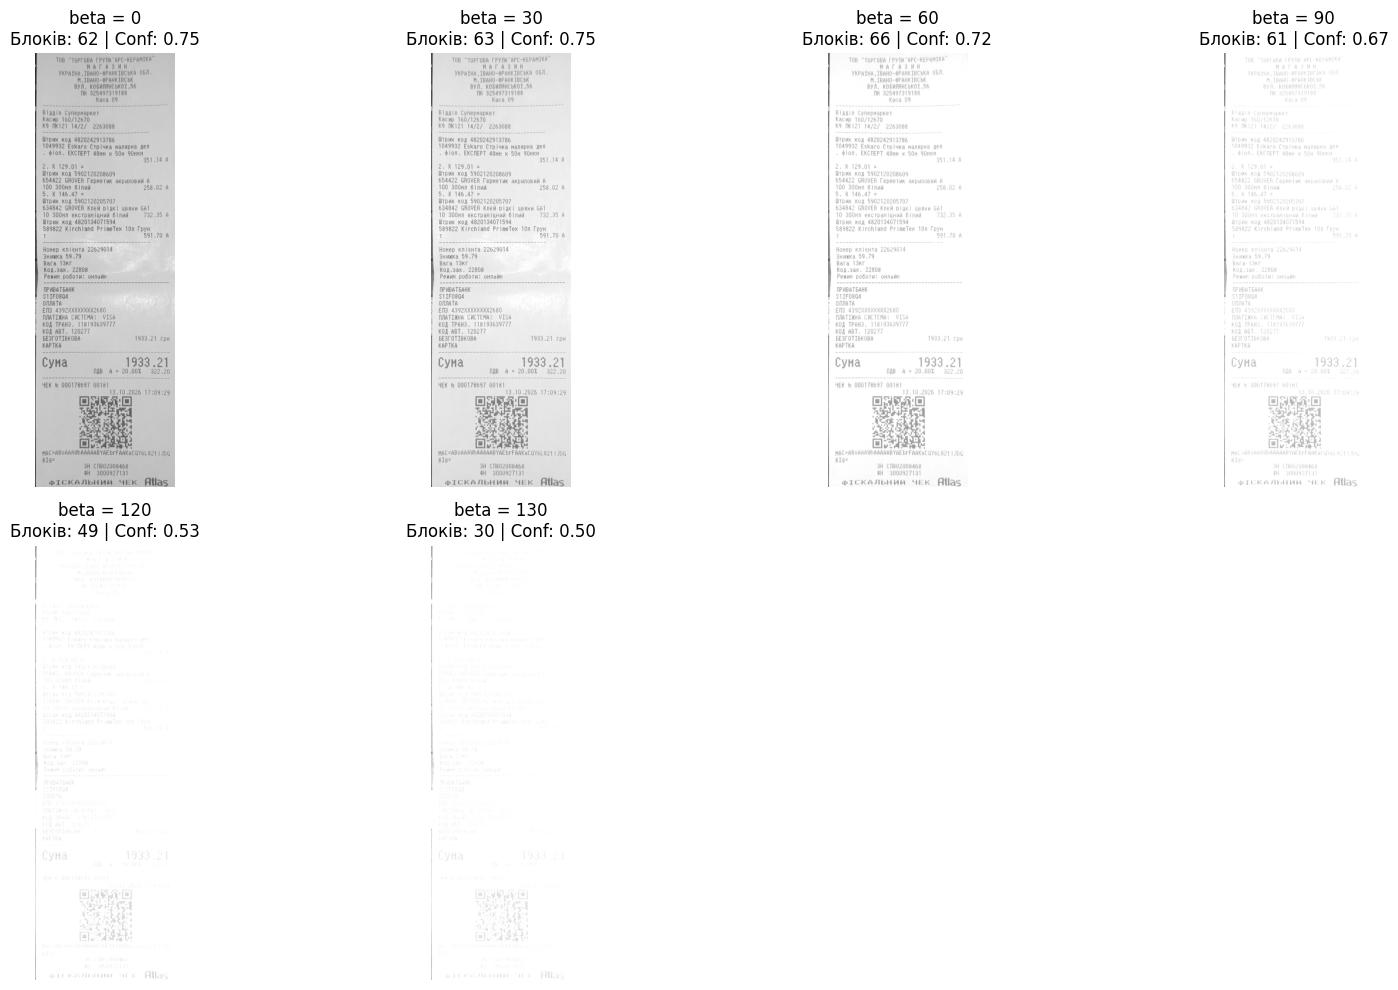

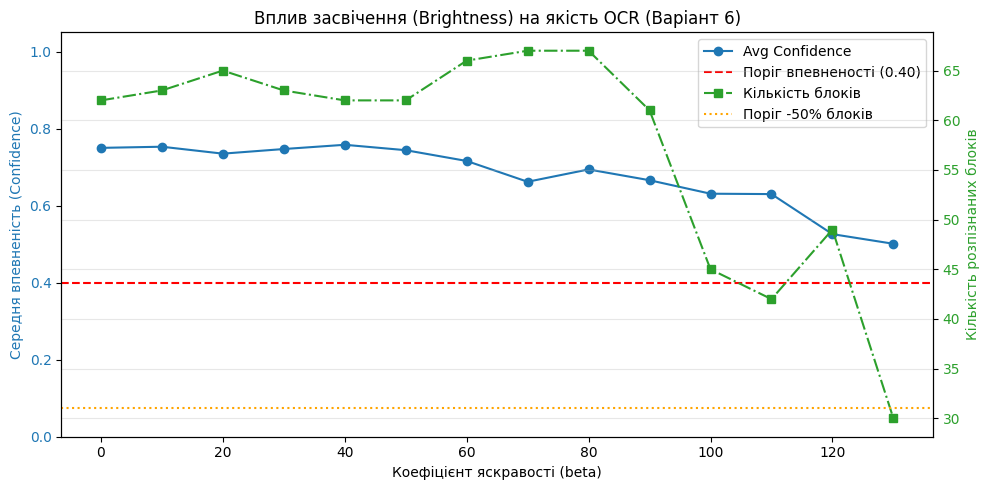

In [33]:
import pandas as pd

# Перевіряємо, що gray_img та reader вже існують
if "gray_img" not in locals():
    raise RuntimeError("Спочатку завантаж зображення у змінну gray_img.")

# Базовий запуск OCR на незміненому gray_img (beta = 0)
orig_results = reader.readtext(gray_img)
orig_confs = [conf for _, _, conf in orig_results if conf > 0.3]
orig_blocks_count = len(orig_confs)
orig_avg_conf = sum(orig_confs) / orig_blocks_count if orig_blocks_count > 0 else 0.0

threshold_confidence = 0.40
min_blocks_threshold = orig_blocks_count * 0.5  # Зменшення кількості блоків на 50%

beta = 0
step = 10

history = []
visual_samples = []

print("[*] Запуск експерименту (Варіант 6: Засвічення / Brightness)")
print(f"[*] Оригінал: блоків = {orig_blocks_count}, середня впевненість = {orig_avg_conf:.2f}")
print(f"[*] Критерії зупинки: Avg Confidence < {threshold_confidence} АБО блоків <= {min_blocks_threshold:.1f}\n")

while beta <= 255:
    degraded_img = cv2.convertScaleAbs(gray_img, alpha=1.0, beta=beta)
    results = reader.readtext(degraded_img)

    valid_confs = [conf for _, _, conf in results if conf > 0.3]
    blocks_count = len(valid_confs)
    avg_conf = sum(valid_confs) / blocks_count if blocks_count > 0 else 0.0
    pct_from_orig = (blocks_count / orig_blocks_count) * 100 if orig_blocks_count > 0 else 0.0

    history.append({
        "Beta (яскравість)": beta,
        "Розпізнано блоків": blocks_count,
        "Відсоток від оригіналу (%)": round(pct_from_orig, 1),
        "Середня впевненість": round(avg_conf, 3),
    })

    print(
        f"beta = {beta:3d} | Блоків: {blocks_count:2d} ({pct_from_orig:5.1f}%) | "
        f"Avg Conf: {avg_conf:.3f}"
    )

    if beta % 30 == 0 or avg_conf < threshold_confidence or blocks_count <= min_blocks_threshold:
        visual_samples.append((beta, degraded_img, blocks_count, avg_conf))

    if beta > 0 and (avg_conf < threshold_confidence or blocks_count <= min_blocks_threshold):
        print(f"\n[!] Досягнуто межу відмовостійкості при beta = {beta}")
        break

    beta += step

df_results = pd.DataFrame(history)
display(df_results)

# 1. Візуалізація етапів засвічення зображення
num_samples = len(visual_samples)
cols = min(4, max(1, num_samples))
rows = (num_samples + cols - 1) // cols

plt.figure(figsize=(4 * cols, 5 * rows))
for idx, (b_val, d_img, b_cnt, a_conf) in enumerate(visual_samples):
    plt.subplot(rows, cols, idx + 1)
    plt.imshow(d_img, cmap="gray", vmin=0, vmax=255)
    plt.title(f"beta = {b_val}\nБлоків: {b_cnt} | Conf: {a_conf:.2f}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# 2. Графік динаміки падіння точності та кількості блоків
fig, ax1 = plt.subplots(figsize=(10, 5))

color1 = "tab:blue"
ax1.set_xlabel("Коефіцієнт яскравості (beta)")
ax1.set_ylabel("Середня впевненість (Confidence)", color=color1)
line1 = ax1.plot(
    df_results["Beta (яскравість)"],
    df_results["Середня впевненість"],
    marker="o",
    color=color1,
    label="Avg Confidence",
)
ref1 = ax1.axhline(y=0.40, color="red", linestyle="--", label="Поріг впевненості (0.40)")
ax1.tick_params(axis="y", labelcolor=color1)
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
color2 = "tab:green"
ax2.set_ylabel("Кількість розпізнаних блоків", color=color2)
line2 = ax2.plot(
    df_results["Beta (яскравість)"],
    df_results["Розпізнано блоків"],
    marker="s",
    linestyle="-.",
    color=color2,
    label="Кількість блоків",
)
ref2 = ax2.axhline(
    y=min_blocks_threshold,
    color="orange",
    linestyle=":",
    label="Поріг -50% блоків",
)
ax2.tick_params(axis="y", labelcolor=color2)

lines = line1 + [ref1] + line2 + [ref2]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best")

plt.title("Вплив засвічення (Brightness) на якість OCR (Варіант 6)")
fig.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()